In [5]:
import sys
sys.path.append('..')

import joblib, shap, pandas as pd
import matplotlib.pyplot as plt
from src.splits import time_split


In [6]:
b = joblib.load('../models/bundle.joblib')
df = pd.read_parquet('../data/processed/features.parquet')
_, _, test = time_split(df)

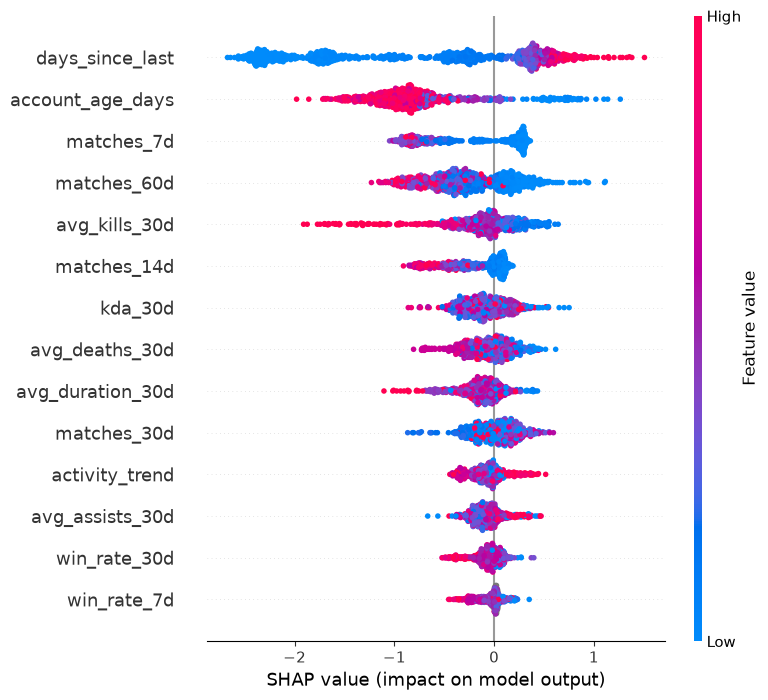

In [7]:
sample_size = min(2000, len(test))
X = test[b['features']].sample(sample_size, random_state=0)
sv = shap.TreeExplainer(b['model']).shap_values(X)
shap.summary_plot(sv, X, show=False)
plt.savefig('../docs/shap_summary.png', bbox_inches='tight')